In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import ccxt

import warnings
warnings.filterwarnings("ignore")

In [2]:
binance = ccxt.binance()

In [3]:
binance

ccxt.binance()

In [4]:
ena = binance.fetch_ohlcv("ENA/USDT", timeframe='1d', limit=1000) 

# Let's convert in into pandas dataframe
ena_ohlcv = pd.DataFrame(ena, columns=['date', 'open', 'high', 'low', 'close', 'volume'])
ena_ohlcv["date"] = pd.to_datetime(ena_ohlcv["date"], unit="ms")

In [5]:
ena_ohlcv.head()

,date,open,high,low,close,volume
0,2024-04-02,0.300,0.913,0.300,0.775,1.550712e+09
1,2024-04-03,0.775,1.320,0.703,1.134,1.339413e+09
2,2024-04-04,1.134,1.168,0.907,0.970,6.469176e+08
3,2024-04-05,0.970,1.069,0.861,1.018,5.022287e+08
4,2024-04-06,1.018,1.194,0.962,1.089,4.155506e+08


In [7]:
ena_ohlcv.tail()

,date,open,high,low,close,volume
642,2026-01-04,0.2391,0.2526,0.2377,0.2507,1.111553e+08
643,2026-01-05,0.2506,0.2592,0.2385,0.2527,1.954056e+08
644,2026-01-06,0.2527,0.2633,0.2410,0.2569,2.254839e+08
645,2026-01-07,0.2568,0.2570,0.2342,0.2380,1.664102e+08
646,2026-01-08,0.2381,0.2399,0.2272,0.2368,8.115316e+07


In [8]:
#ena_ohlcv.to_csv("ena_ohlcv.csv", index = False)

In [9]:
ena_ohlcv.set_index("date", inplace=True)

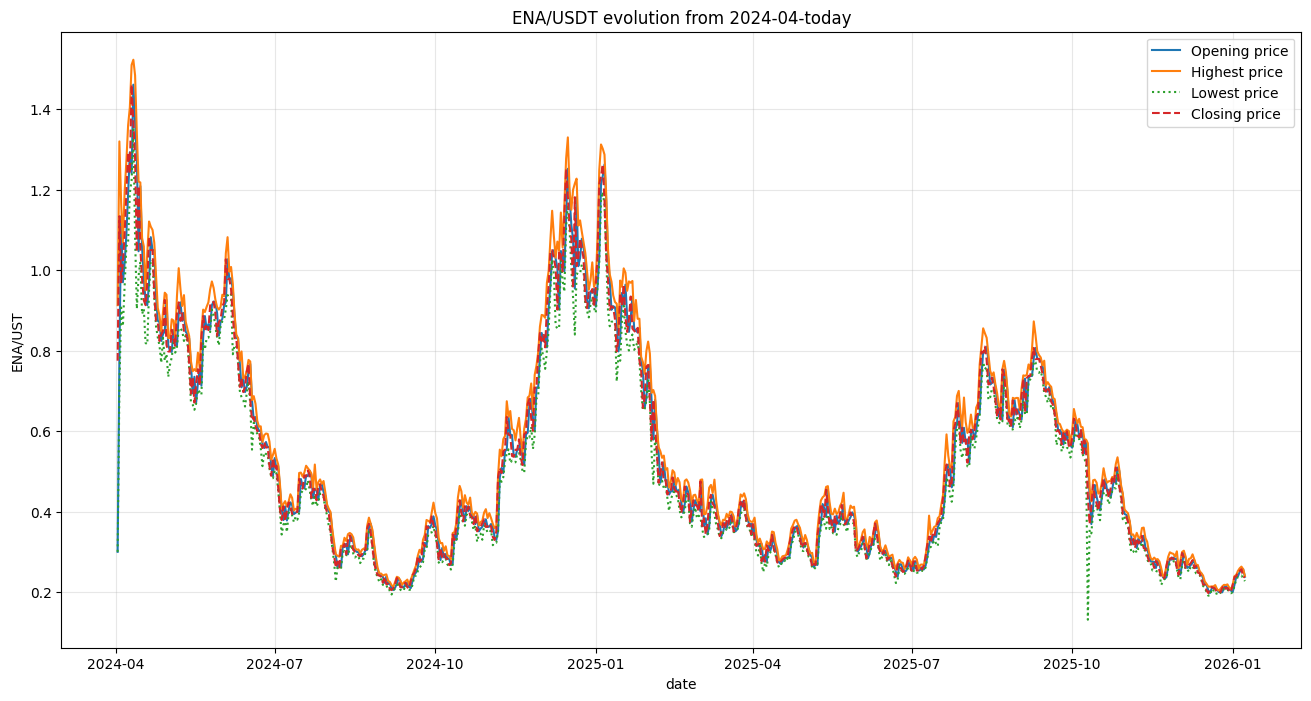

In [10]:
plt.figure(figsize = (16, 8))
plt.title("ENA/USDT evolution from 2024-04-today")
plt.plot(ena_ohlcv.index, ena_ohlcv.open, label = "Opening price")
plt.plot(ena_ohlcv.index, ena_ohlcv.high, label = "Highest price", linestyle = "-")
plt.plot(ena_ohlcv.index, ena_ohlcv.low, label = "Lowest price", linestyle = ":")
plt.plot(ena_ohlcv.index, ena_ohlcv.close, label = "Closing price", linestyle = "dashed")
plt.xlabel("date")
plt.ylabel("ENA/UST")
plt.grid(alpha = 0.3)
plt.legend()
plt.show()

In [11]:
corr = ena_ohlcv.corr()
corr

,open,high,low,close,volume
open,1.000000,0.987722,0.991011,0.981887,0.206459
high,0.987722,1.000000,0.983413,0.994632,0.301457
low,0.991011,0.983413,1.000000,0.987002,0.177844
close,0.981887,0.994632,0.987002,1.000000,0.270632
volume,0.206459,0.301457,0.177844,0.270632,1.000000


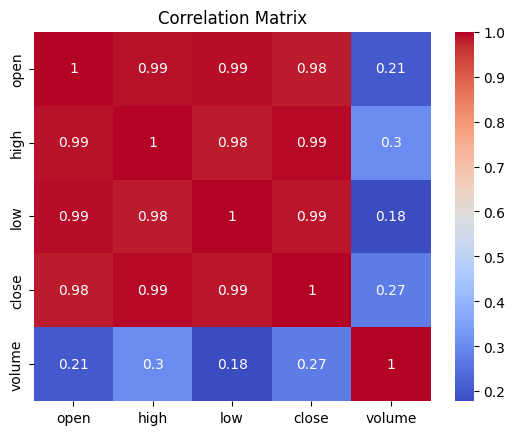

In [12]:
plt.title("Correlation Matrix")
sns.heatmap(corr, annot=True, cmap = "coolwarm")
plt.show()

**ENA/USDT ne montre pas de grandre variation intrajournalière**

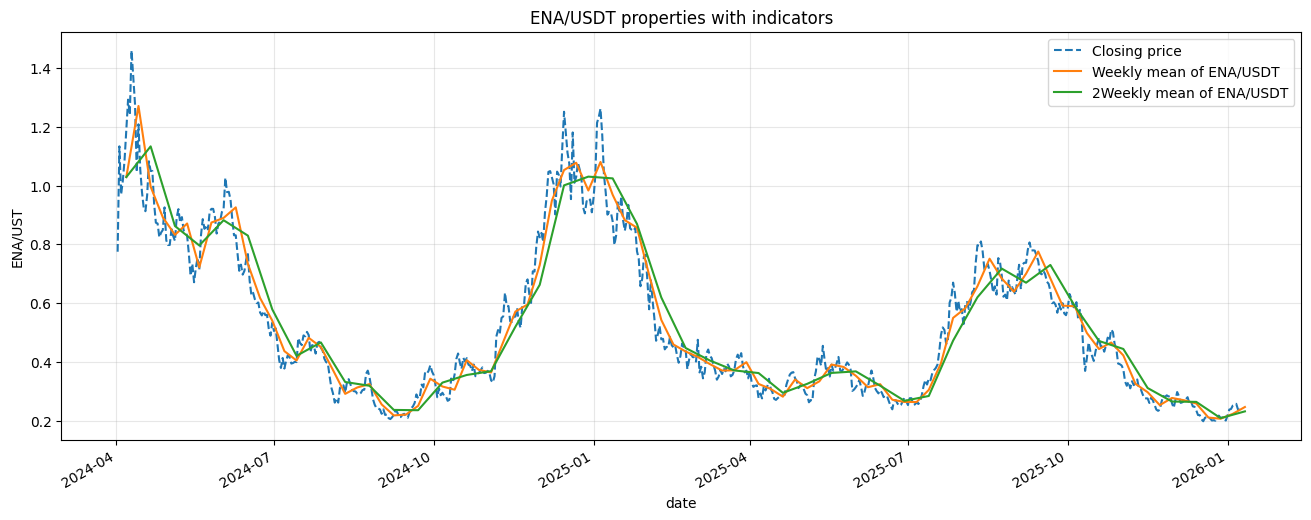

In [13]:
plt.figure(figsize = (16, 6))
plt.title("ENA/USDT properties with indicators")
plt.plot(ena_ohlcv.index, ena_ohlcv.close, label = "Closing price", linestyle = "dashed")
ena_ohlcv["close"].resample("w").mean().plot(label = "Weekly mean of ENA/USDT")
ena_ohlcv["close"].resample("2w").mean().plot(label = "2Weekly mean of ENA/USDT")
plt.xlabel("date")
plt.ylabel("ENA/UST")
plt.grid(alpha = 0.3)
plt.legend()
plt.show()

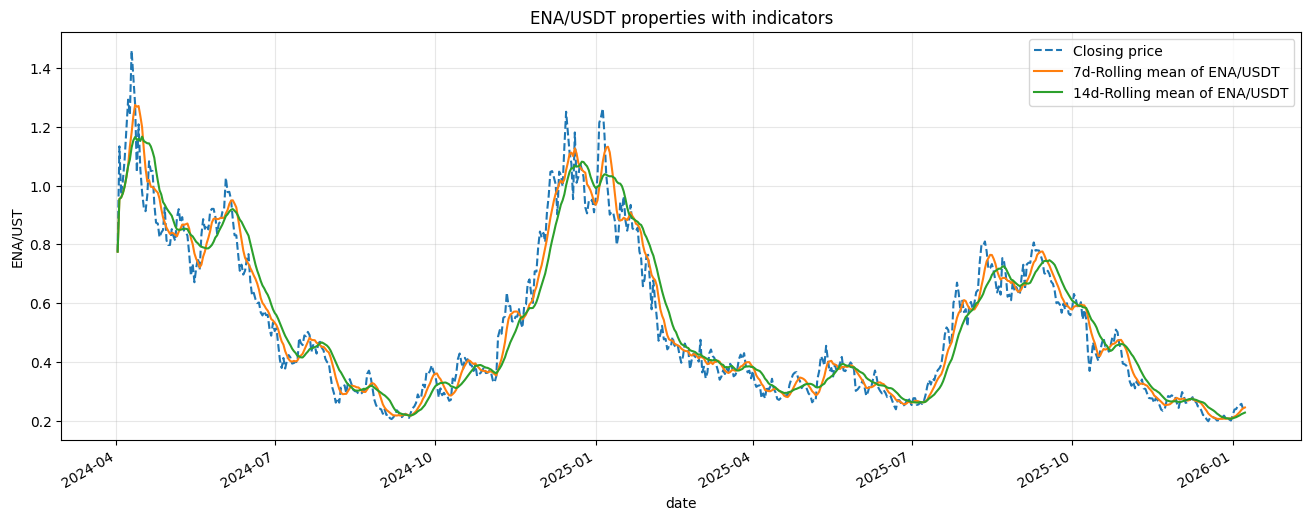

In [14]:
plt.figure(figsize = (16, 6))
plt.title("ENA/USDT properties with indicators")
plt.plot(ena_ohlcv.index, ena_ohlcv.close, label = "Closing price", linestyle = "dashed")
ena_ohlcv["close"].rolling(window = 7, min_periods = 1).mean().plot(label = "7d-Rolling mean of ENA/USDT")
ena_ohlcv["close"].rolling(window = 14, min_periods = 1).mean().plot(label = "14d-Rolling mean of ENA/USDT")
plt.xlabel("date")
plt.ylabel("ENA/UST")
plt.grid(alpha = 0.3)
plt.legend()
plt.show()

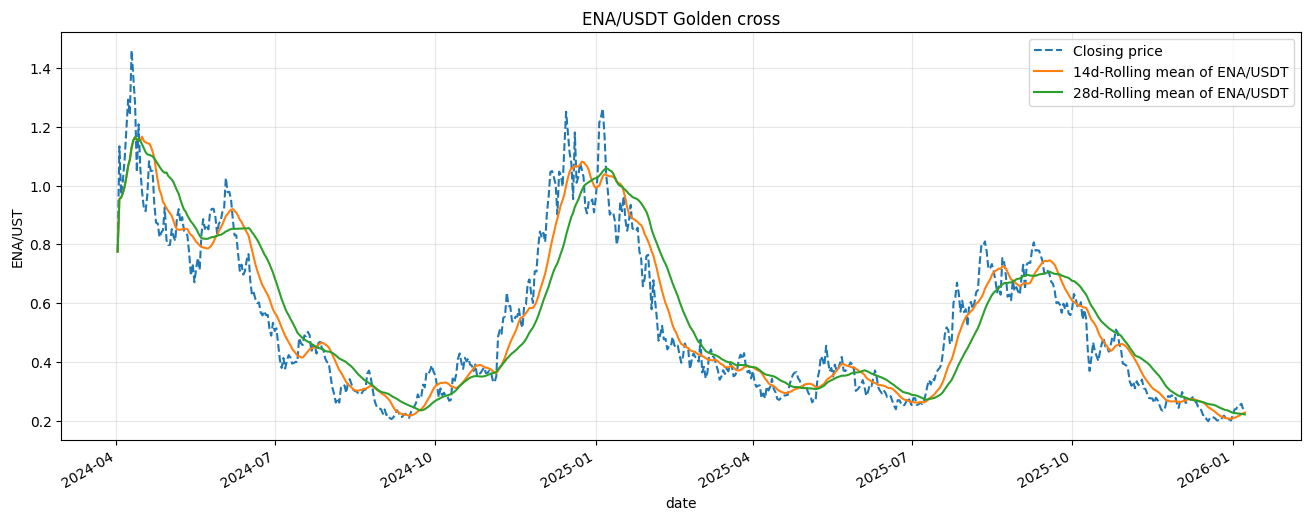

In [15]:
plt.figure(figsize = (16, 6))
plt.title("ENA/USDT Golden cross")
plt.plot(ena_ohlcv.index, ena_ohlcv.close, label = "Closing price", linestyle = "dashed")
ena_ohlcv["close"].rolling(window = 14, min_periods = 1).mean().plot(label = "14d-Rolling mean of ENA/USDT")
ena_ohlcv["close"].rolling(window = 28, min_periods = 1).mean().plot(label = "28d-Rolling mean of ENA/USDT")
plt.xlabel("date")
plt.ylabel("ENA/UST")
plt.grid(alpha = 0.3)
plt.legend()
plt.show()

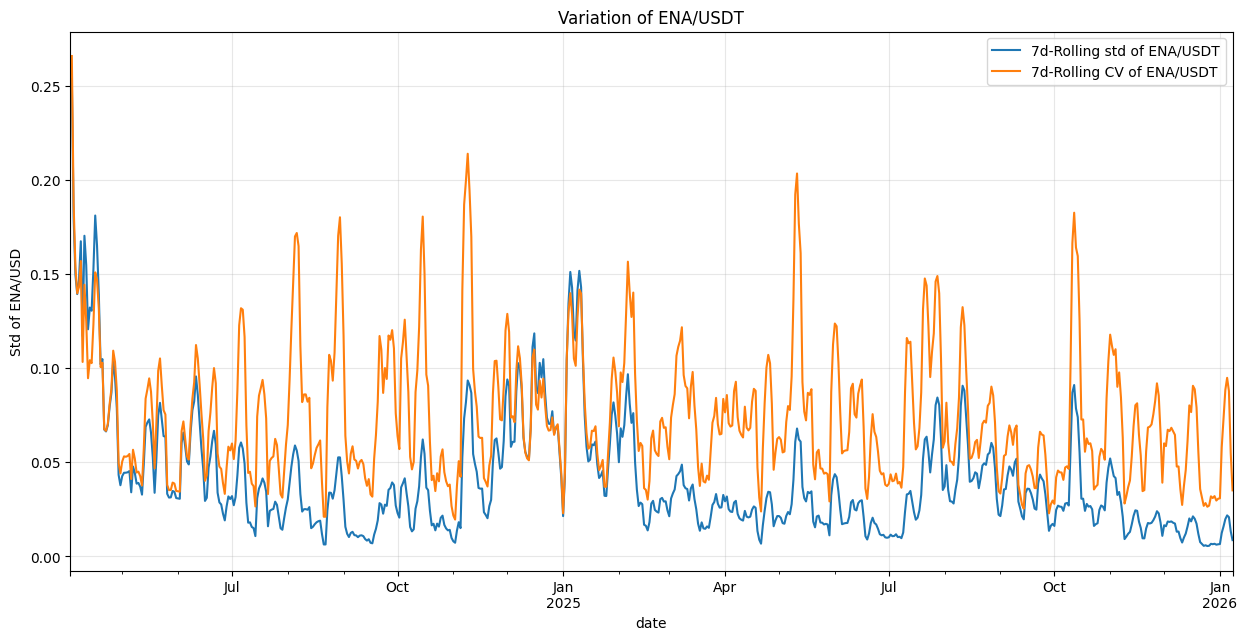

In [16]:
plt.figure(figsize=(15, 7))
plt.title("Variation of ENA/USDT")
ena_ohlcv["close"].rolling(window = 7, min_periods = 1).std().plot(label = "7d-Rolling std of ENA/USDT")
(ena_ohlcv["close"].rolling(window = 7, min_periods = 1).std()/ena_ohlcv["close"].rolling(window = 7, min_periods = 1).mean()).plot(label = "7d-Rolling CV of ENA/USDT")
plt.ylabel("Std of ENA/USD")
plt.xlabel("date")
plt.legend()
plt.grid(alpha = 0.3)
plt.show()

In [17]:
ena_ohlcv.shape

(647, 5)

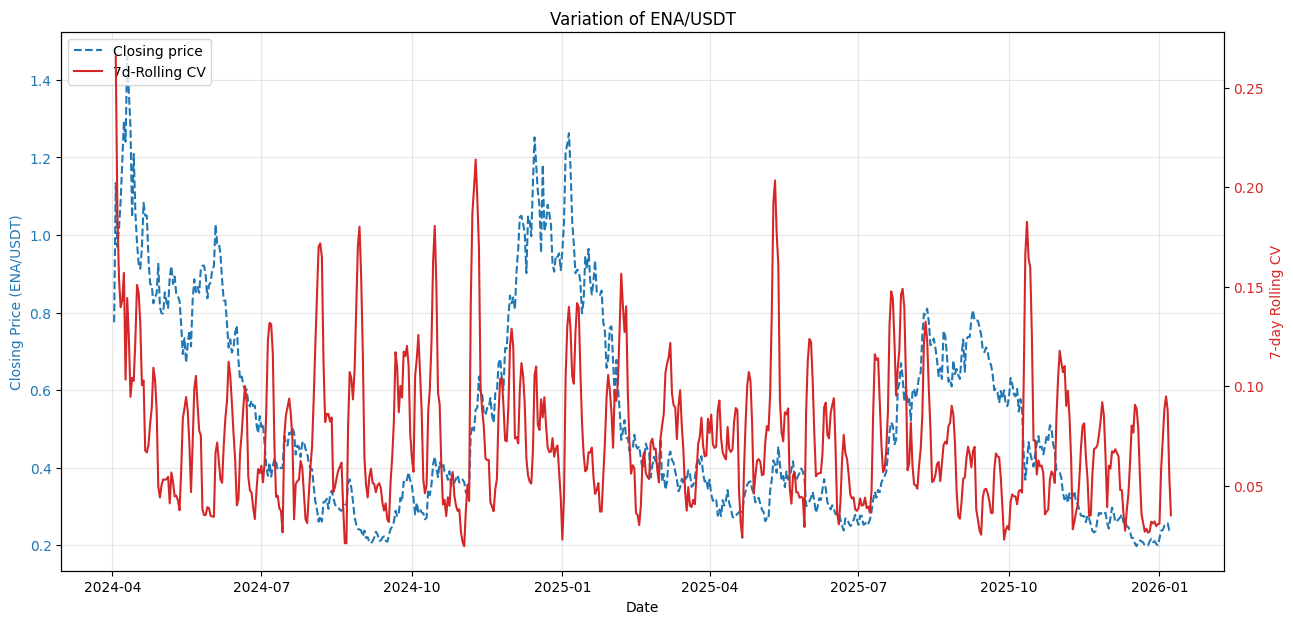

In [18]:
plt.figure(figsize=(15, 7))
plt.title("Variation of ENA/USDT")

# Axe principal (gauche)
ax1 = plt.gca()
ax1.plot(ena_ohlcv.index, ena_ohlcv["close"], 
         label="Closing price", color="tab:blue", linestyle="dashed")
ax1.set_xlabel("Date")
ax1.set_ylabel("Closing Price (ENA/USDT)", color="tab:blue")
ax1.tick_params(axis='y', labelcolor="tab:blue")
ax1.grid(alpha=0.3)

# Axe secondaire (droite)
ax2 = ax1.twinx()
cv = (ena_ohlcv["close"].rolling(window=7, min_periods=1).std() /
      ena_ohlcv["close"].rolling(window=7, min_periods=1).mean())
ax2.plot(ena_ohlcv.index, cv, label="7d-Rolling CV", color="tab:red")
ax2.set_ylabel("7-day Rolling CV", color="tab:red")
ax2.tick_params(axis='y', labelcolor="tab:red")

# Légendes combinées
lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()
ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc="upper left")

plt.show()

In [19]:
ena_ohlcv["close"].pct_change()

date
2024-04-02         NaN
2024-04-03    0.463226
2024-04-04   -0.144621
2024-04-05    0.049485
2024-04-06    0.069745
                ...   
2026-01-04    0.048077
2026-01-05    0.007978
2026-01-06    0.016620
2026-01-07   -0.073569
2026-01-08   -0.005042
Name: close, Length: 647, dtype: float64

In [64]:
def feature_engineerin(dataframe, rsi_per = 7, bb_per = 20) :
    data = dataframe.copy()
    date_to_exclude = pd.Timestamp("today").normalize() # Today movement is not over yet so can't be used for inference
    data = data[data.index!=date_to_exclude]
    # Calcul des indicateurs
    # MA
    data["SMA7"] = data["close"].rolling(window = 7, min_periods = 1).mean()
    data["SMA14"] = data["close"].rolling(window = 14, min_periods = 1).mean()
    
    # RSI
    delta = data["close"].diff()
    gain = delta.copy()
    loss = delta.copy()
    gain[gain < 0] = 0 # On ne garde que les hausses
    loss[loss > 0] = 0 # On ne garde que les baisses (en négatif)
    
    avg_gain = gain.rolling(window=rsi_per, min_periods = 1).mean()
    avg_loss = abs(loss.rolling(window=rsi_per, min_periods = 1).mean())
    
    data[f"RSI{rsi_per}"] = avg_gain/(avg_gain+avg_loss)
    
    # MACD (Moving Average Convergence Divergence)
    ema_12 = data['close'].ewm(span=12, adjust=False, min_periods = 1).mean() # Adjust for recursivity
    ema_26 = data['close'].ewm(span=26, adjust=False,min_periods = 1).mean()
    data['MACD'] = ema_12 - ema_26
    data['Signal_Line'] = data['MACD'].ewm(span=9, adjust=False, min_periods = 1).mean()
    data['Histogram'] = data['MACD'] - data['Signal_Line']
    
    # Bollinger Bands
    data["BB_Midle"] = data['close'].rolling(window=bb_per, min_periods = 1).mean()
    bb_rolling_std =  data['close'].rolling(window=bb_per, min_periods = 1).std()
    data["BB_Upper"] = data["BB_Midle"]+(2*bb_rolling_std)
    data["BB_Lower"] = data["BB_Midle"]-(2*bb_rolling_std)
    data["CV"] = data['close'].rolling(window=rsi_per, min_periods = 1).std()/data['close'].rolling(window=rsi_per, min_periods = 1).mean()
    
    # Let's compute the target
    data["lag1_close"] = data["close"].shift(1)
    data["lag1_high"] = data["high"].shift(1)
    data["lag1_low"] = data["low"].shift(1)
    
    return data

In [65]:
eng_ena_data = feature_engineerin(ena_ohlcv)

In [66]:
eng_ena_data

,open,high,low,close,volume,SMA7,SMA14,RSI7,MACD,Signal_Line,Histogram,BB_Midle,BB_Upper,BB_Lower,CV,lag1_close,lag1_high,lag1_low
date,,,,,,,,,,,,,,,,,,
2024-04-02,0.3000,0.9130,0.3000,0.7750,1.550712e+09,0.775000,0.775000,NaN,0.000000,0.000000,0.000000,0.775000,NaN,NaN,NaN,NaN,NaN,NaN
2024-04-03,0.7750,1.3200,0.7030,1.1340,1.339413e+09,0.954500,0.954500,1.000000,0.028638,0.005728,0.022911,0.954500,1.462203,0.446797,0.265952,0.7750,0.9130,0.3000
2024-04-04,1.1340,1.1680,0.9070,0.9700,6.469176e+08,0.959667,0.959667,0.686424,0.037667,0.012115,0.025551,0.959667,1.319113,0.600221,0.187276,1.1340,1.3200,0.7030
2024-04-05,0.9700,1.0690,0.8610,1.0180,5.022287e+08,0.974250,0.974250,0.712785,0.048140,0.019320,0.028820,0.974250,1.273477,0.675023,0.153568,0.9700,1.1680,0.9070
2024-04-06,1.0180,1.1940,0.9620,1.0890,4.155506e+08,0.997200,0.997200,0.744548,0.061461,0.027748,0.033712,0.997200,1.275924,0.718476,0.139753,1.0180,1.0690,0.8610
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-01-04,0.2391,0.2526,0.2377,0.2507,1.111553e+08,0.222729,0.214421,0.832812,-0.004696,-0.012282,0.007586,0.212715,0.241458,0.183972,0.088393,0.2392,0.2422,0.2305
2026-01-05,0.2506,0.2592,0.2385,0.2527,1.954056e+08,0.228743,0.217686,0.831496,-0.002016,-0.010229,0.008213,0.214435,0.248254,0.180616,0.094837,0.2507,0.2526,0.2377
2026-01-06,0.2527,0.2633,0.2410,0.2569,2.254839e+08,0.236343,0.221743,0.937500,0.000443,-0.008094,0.008537,0.217065,0.255440,0.178690,0.087823,0.2527,0.2592,0.2385


In [67]:
# Définition des targets
eng_ena_data["Next_Day_High"] = eng_ena_data["high"].shift(-1)
eng_ena_data['Next_Day_Low'] = eng_ena_data['low'].shift(-1)
eng_ena_data['Next_Day_Close'] = eng_ena_data['close'].shift(-1)

In [68]:
eng_ena_data

,open,high,low,close,volume,SMA7,SMA14,RSI7,MACD,Signal_Line,...,BB_Midle,BB_Upper,BB_Lower,CV,lag1_close,lag1_high,lag1_low,Next_Day_High,Next_Day_Low,Next_Day_Close
date,,,,,,,,,,,,,,,,,,,,,
2024-04-02,0.3000,0.9130,0.3000,0.7750,1.550712e+09,0.775000,0.775000,NaN,0.000000,0.000000,...,0.775000,NaN,NaN,NaN,NaN,NaN,NaN,1.3200,0.7030,1.1340
2024-04-03,0.7750,1.3200,0.7030,1.1340,1.339413e+09,0.954500,0.954500,1.000000,0.028638,0.005728,...,0.954500,1.462203,0.446797,0.265952,0.7750,0.9130,0.3000,1.1680,0.9070,0.9700
2024-04-04,1.1340,1.1680,0.9070,0.9700,6.469176e+08,0.959667,0.959667,0.686424,0.037667,0.012115,...,0.959667,1.319113,0.600221,0.187276,1.1340,1.3200,0.7030,1.0690,0.8610,1.0180
2024-04-05,0.9700,1.0690,0.8610,1.0180,5.022287e+08,0.974250,0.974250,0.712785,0.048140,0.019320,...,0.974250,1.273477,0.675023,0.153568,0.9700,1.1680,0.9070,1.1940,0.9620,1.0890
2024-04-06,1.0180,1.1940,0.9620,1.0890,4.155506e+08,0.997200,0.997200,0.744548,0.061461,0.027748,...,0.997200,1.275924,0.718476,0.139753,1.0180,1.0690,0.8610,1.2710,1.0590,1.1900
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-01-04,0.2391,0.2526,0.2377,0.2507,1.111553e+08,0.222729,0.214421,0.832812,-0.004696,-0.012282,...,0.212715,0.241458,0.183972,0.088393,0.2392,0.2422,0.2305,0.2592,0.2385,0.2527
2026-01-05,0.2506,0.2592,0.2385,0.2527,1.954056e+08,0.228743,0.217686,0.831496,-0.002016,-0.010229,...,0.214435,0.248254,0.180616,0.094837,0.2507,0.2526,0.2377,0.2633,0.2410,0.2569
2026-01-06,0.2527,0.2633,0.2410,0.2569,2.254839e+08,0.236343,0.221743,0.937500,0.000443,-0.008094,...,0.217065,0.255440,0.178690,0.087823,0.2527,0.2592,0.2385,0.2570,0.2342,0.2380


In [69]:
eng_ena_data.dtypes

open              float64
high              float64
low               float64
close             float64
volume            float64
SMA7              float64
SMA14             float64
RSI7              float64
MACD              float64
Signal_Line       float64
Histogram         float64
BB_Midle          float64
BB_Upper          float64
BB_Lower          float64
CV                float64
lag1_close        float64
lag1_high         float64
lag1_low          float64
Next_Day_High     float64
Next_Day_Low      float64
Next_Day_Close    float64
dtype: object

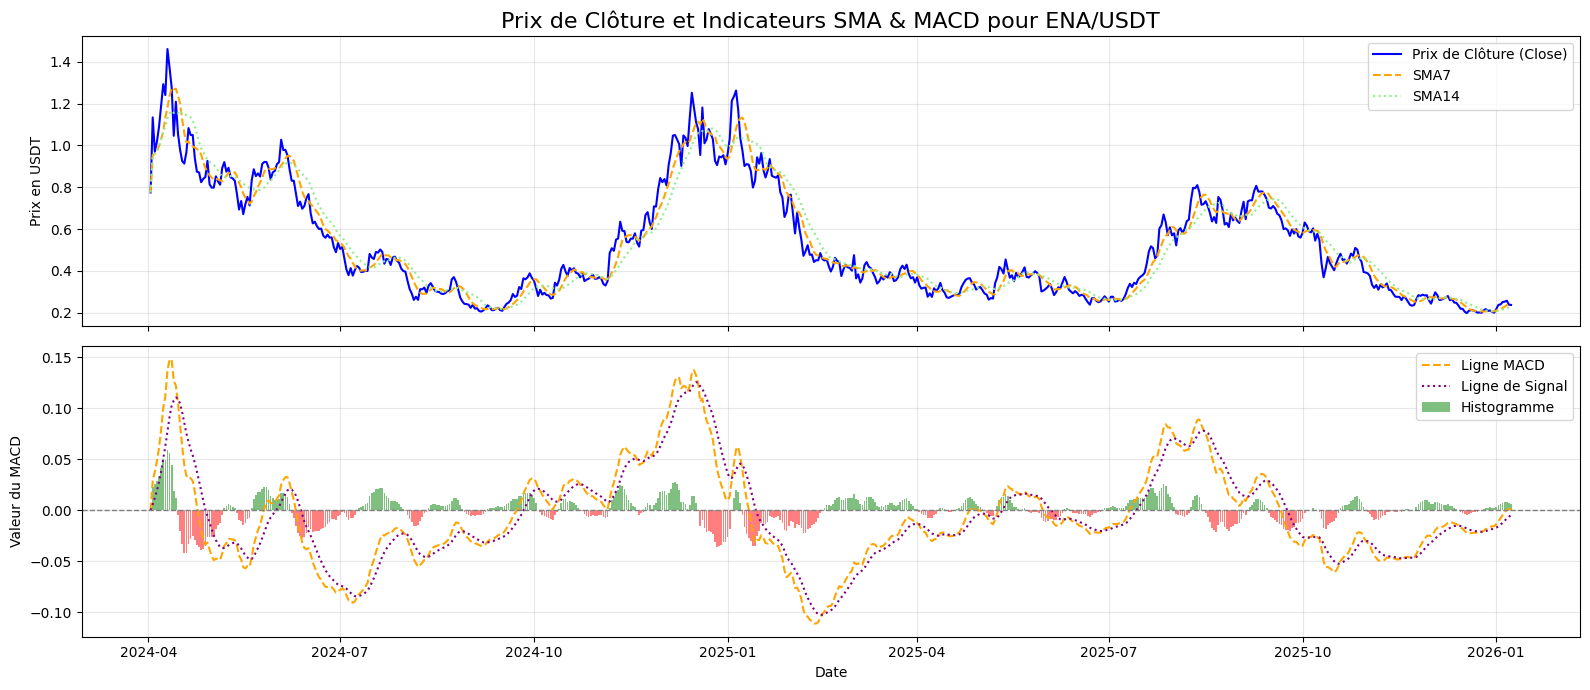

In [70]:
# Visualisation des lignes MACD, Signal et Histogram
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(16, 7), sharex=True)

# --- Premier graphique (ax1) : Le Prix ---
ax1.set_title("Prix de Clôture et Indicateurs SMA & MACD pour ENA/USDT", fontsize=16)
ax1.plot(eng_ena_data.index, eng_ena_data['close'], label="Prix de Clôture (Close)", color='blue')
ax1.plot(eng_ena_data.index, eng_ena_data['SMA7'], label="SMA7", color='orange', linestyle='--')
ax1.plot(eng_ena_data.index, eng_ena_data['SMA14'], label="SMA14", color='lightgreen', linestyle=':')
ax1.set_ylabel("Prix en USDT")
ax1.legend()
ax1.grid(alpha=0.3)

# --- Second graphique (ax2) : L'indicateur MACD ---
# On trace les lignes MACD et Signal
ax2.plot(eng_ena_data.index, eng_ena_data['MACD'], label="Ligne MACD", color='orange', linestyle='--')
ax2.plot(eng_ena_data.index, eng_ena_data['Signal_Line'], label="Ligne de Signal", color='purple', linestyle=':')

# Pour l'histogramme, un bar chart est beaucoup plus visuel et standard
# On colore les barres en vert si > 0 et en rouge si < 0
colors = ['green' if val >= 0 else 'red' for val in eng_ena_data['Histogram']]
ax2.bar(eng_ena_data.index, eng_ena_data['Histogram'], label="Histogramme", color=colors, alpha=0.5)

# On ajoute une ligne horizontale à zéro pour mieux voir les croisements
ax2.axhline(0, color='gray', linestyle='--', linewidth=1)

ax2.set_ylabel("Valeur du MACD")
ax2.set_xlabel("Date")
ax2.legend()
ax2.grid(alpha=0.3)

# Ajuste automatiquement les plots pour qu'ils ne se chevauchent pas
plt.tight_layout()

# Affiche la figure complète
plt.show()

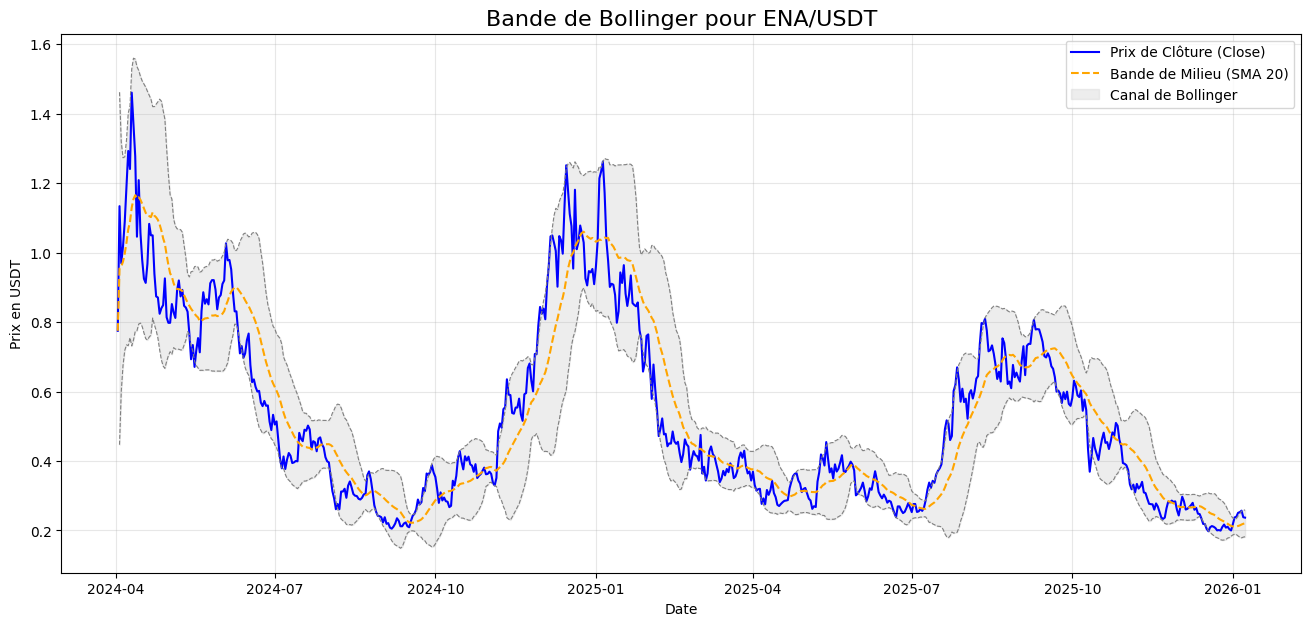

In [71]:
plt.figure(figsize=(16, 7))
plt.title("Bande de Bollinger pour ENA/USDT", fontsize=16)

# On trace le prix de clôture et la bande du milieu comme avant
plt.plot(eng_ena_data.index, eng_ena_data['close'], label="Prix de Clôture (Close)", color='blue', linewidth=1.5)
plt.plot(eng_ena_data.index, eng_ena_data['BB_Midle'], label="Bande de Milieu (SMA 20)", color='orange', linestyle='--')

# On trace les bandes supérieure et inférieure, mais sans label car la zone remplie les représentera
plt.plot(eng_ena_data.index, eng_ena_data['BB_Upper'], color='gray', linestyle='--', linewidth=0.8)
plt.plot(eng_ena_data.index, eng_ena_data['BB_Lower'], color='gray', linestyle='--', linewidth=0.8)

# --- LA LIGNE QUE VOUS VOULEZ COMPLÉTER ---
# On remplit l'espace entre la bande supérieure et inférieure
plt.fill_between(
    eng_ena_data.index,          # Les valeurs de l'axe X
    eng_ena_data['BB_Lower'],    # La limite inférieure du remplissage
    eng_ena_data['BB_Upper'],    # La limite supérieure du remplissage
    color='lightgray',           # Couleur de la zone hachurée
    alpha=0.4,                   # Niveau de transparence (entre 0 et 1)
    label='Canal de Bollinger'   # Label pour la légende
)
# -------------------------------------------

plt.xlabel("Date")
plt.ylabel("Prix en USDT")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Modélisation Multi-ouputs des objectifs

In [72]:
# Modélisation de Close
eng_ena_data.head(2)

,open,high,low,close,volume,SMA7,SMA14,RSI7,MACD,Signal_Line,...,BB_Midle,BB_Upper,BB_Lower,CV,lag1_close,lag1_high,lag1_low,Next_Day_High,Next_Day_Low,Next_Day_Close
date,,,,,,,,,,,,,,,,,,,,,
2024-04-02,0.300,0.913,0.300,0.775,1.550712e+09,0.7750,0.7750,NaN,0.000000,0.000000,...,0.7750,NaN,NaN,NaN,NaN,NaN,NaN,1.320,0.703,1.134
2024-04-03,0.775,1.320,0.703,1.134,1.339413e+09,0.9545,0.9545,1.0,0.028638,0.005728,...,0.9545,1.462203,0.446797,0.265952,0.775,0.913,0.3,1.168,0.907,0.970


In [73]:
eng_ena_data.tail(2)

,open,high,low,close,volume,SMA7,SMA14,RSI7,MACD,Signal_Line,...,BB_Midle,BB_Upper,BB_Lower,CV,lag1_close,lag1_high,lag1_low,Next_Day_High,Next_Day_Low,Next_Day_Close
date,,,,,,,,,,,,,,,,,,,,,
2026-01-07,0.2568,0.2570,0.2342,0.2380,1.664102e+08,0.241786,0.224386,0.750988,0.000856,-0.006304,...,0.219085,0.257399,0.180771,0.054771,0.2569,0.2633,0.2410,0.2399,0.2272,0.2368
2026-01-08,0.2381,0.2399,0.2272,0.2368,8.115316e+07,0.244529,0.227050,0.661616,0.001074,-0.004828,...,0.220470,0.259264,0.181676,0.034999,0.2380,0.2570,0.2342,NaN,NaN,NaN


In [74]:
eng_ena_data.index.max()

Timestamp('2026-01-08 00:00:00')

In [75]:
last_date_ena = eng_ena_data.index.max()
td_obj_features = eng_ena_data.drop(["Next_Day_High", "Next_Day_Low", "Next_Day_Close"], axis = 1).loc[last_date_ena].values.reshape(1,-1)

In [76]:
eng_ena_data.dropna(inplace = True)

In [77]:
# Sélection de modèles
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor, ExtraTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from lightgbm import LGBMRegressor
from sklearn.preprocessing import MinMaxScaler
from sklearn.multioutput import MultiOutputRegressor
from sklearn.metrics import r2_score, mean_absolute_percentage_error

In [78]:
models = {"lr": MultiOutputRegressor(LinearRegression()), "ridge": MultiOutputRegressor(Ridge()), "lasso":MultiOutputRegressor(Lasso()), 
          "dtr": MultiOutputRegressor(DecisionTreeRegressor()), "etr": MultiOutputRegressor(ExtraTreeRegressor()), "rfr": MultiOutputRegressor(RandomForestRegressor()),
         "gbr": MultiOutputRegressor(GradientBoostingRegressor()), "svr": MultiOutputRegressor(SVR()), "knn":MultiOutputRegressor(KNeighborsRegressor()), 
         "lgbm": MultiOutputRegressor(LGBMRegressor(verbose = -2))}

In [79]:
# Let's divide data
train_idx = int(len(eng_ena_data)*0.8)
X_train, y_train = eng_ena_data.drop(["Next_Day_High", "Next_Day_Low", "Next_Day_Close"], axis = 1).iloc[:train_idx], eng_ena_data[["Next_Day_High", "Next_Day_Low", "Next_Day_Close"]].iloc[:train_idx]
X_test, y_test = eng_ena_data.drop(["Next_Day_High", "Next_Day_Low", "Next_Day_Close"], axis = 1).iloc[train_idx:], eng_ena_data[["Next_Day_High", "Next_Day_Low", "Next_Day_Close"]].iloc[train_idx:]

In [80]:
X_train.tail()

,open,high,low,close,volume,SMA7,SMA14,RSI7,MACD,Signal_Line,Histogram,BB_Midle,BB_Upper,BB_Lower,CV,lag1_close,lag1_high,lag1_low
date,,,,,,,,,,,,,,,,,,
2025-08-27,0.6290,0.6362,0.6040,0.6097,1.981510e+08,0.668157,0.680371,0.423696,0.014965,0.035319,-0.020354,0.704220,0.831979,0.576461,0.090166,0.6289,0.6432,0.6171
2025-08-28,0.6097,0.6828,0.6042,0.6767,2.235220e+08,0.674986,0.677571,0.568403,0.014639,0.031183,-0.016544,0.705830,0.831210,0.580450,0.085497,0.6097,0.6362,0.6040
2025-08-29,0.6768,0.6806,0.6290,0.6413,2.698847e+08,0.658986,0.671993,0.284946,0.011392,0.027225,-0.015832,0.701080,0.828776,0.573384,0.071154,0.6767,0.6828,0.6042
2025-08-30,0.6414,0.6825,0.6238,0.6545,1.080656e+08,0.646757,0.666386,0.335637,0.009772,0.023734,-0.013962,0.693940,0.814768,0.573112,0.047176,0.6413,0.6806,0.6290
2025-08-31,0.6545,0.6824,0.6387,0.6398,1.099042e+08,0.638943,0.661421,0.380828,0.007219,0.020431,-0.013212,0.686185,0.799398,0.572972,0.034569,0.6545,0.6825,0.6238


In [81]:
X_test.head()

,open,high,low,close,volume,SMA7,SMA14,RSI7,MACD,Signal_Line,Histogram,BB_Midle,BB_Upper,BB_Lower,CV,lag1_close,lag1_high,lag1_low
date,,,,,,,,,,,,,,,,,,
2025-09-01,0.6398,0.6526,0.6075,0.6287,1.370945e+08,0.639943,0.657957,0.520858,0.004250,0.017195,-0.012944,0.677120,0.776817,0.577423,0.033319,0.6398,0.6824,0.6387
2025-09-02,0.6287,0.7058,0.6284,0.6875,2.933960e+08,0.648314,0.661621,0.633546,0.006567,0.015069,-0.008502,0.672685,0.761075,0.584295,0.041661,0.6287,0.6526,0.6075
2025-09-03,0.6876,0.7386,0.6754,0.7306,1.943642e+08,0.665586,0.666871,0.748459,0.011745,0.014404,-0.002659,0.673420,0.763550,0.583290,0.053362,0.6875,0.7058,0.6284
2025-09-04,0.7306,0.7375,0.6404,0.6473,2.036000e+08,0.661386,0.668186,0.443374,0.009023,0.013328,-0.004305,0.669815,0.757947,0.581683,0.054010,0.7306,0.7386,0.6754
2025-09-05,0.6473,0.7397,0.6441,0.7319,3.849398e+08,0.674329,0.666657,0.646697,0.013537,0.013370,0.000167,0.669760,0.757727,0.581793,0.063647,0.6473,0.7375,0.6404


In [82]:
X_train.head()

,open,high,low,close,volume,SMA7,SMA14,RSI7,MACD,Signal_Line,Histogram,BB_Midle,BB_Upper,BB_Lower,CV,lag1_close,lag1_high,lag1_low
date,,,,,,,,,,,,,,,,,,
2024-04-03,0.775,1.320,0.703,1.134,1.339413e+09,0.954500,0.954500,1.000000,0.028638,0.005728,0.022911,0.954500,1.462203,0.446797,0.265952,0.775,0.913,0.300
2024-04-04,1.134,1.168,0.907,0.970,6.469176e+08,0.959667,0.959667,0.686424,0.037667,0.012115,0.025551,0.959667,1.319113,0.600221,0.187276,1.134,1.320,0.703
2024-04-05,0.970,1.069,0.861,1.018,5.022287e+08,0.974250,0.974250,0.712785,0.048140,0.019320,0.028820,0.974250,1.273477,0.675023,0.153568,0.970,1.168,0.907
2024-04-06,1.018,1.194,0.962,1.089,4.155506e+08,0.997200,0.997200,0.744548,0.061461,0.027748,0.033712,0.997200,1.275924,0.718476,0.139753,1.018,1.069,0.861
2024-04-07,1.089,1.271,1.059,1.190,4.166273e+08,1.029333,1.029333,0.779273,0.079254,0.038049,0.041204,1.029333,1.324173,0.734493,0.143219,1.089,1.194,0.962


In [83]:
X_train.shape, y_train.shape, X_test.shape, y_test.shape

((516, 18), (516, 3), (129, 18), (129, 3))

In [84]:
y_train.head()

,Next_Day_High,Next_Day_Low,Next_Day_Close
date,,,
2024-04-03,1.168,0.907,0.970
2024-04-04,1.069,0.861,1.018
2024-04-05,1.194,0.962,1.089
2024-04-06,1.271,1.059,1.190
2024-04-07,1.360,1.070,1.293


In [85]:
scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [115]:
all_train_mape = []
all_train_r2 = []
all_test_mape = []
all_test_r2 = []

for name, model in models.items() :
    print("="*30+f" Modeling with {name} "+"="*30)
    
    # modeling
    model.fit(X_train_scaled, y_train)
    
    # Metric computing
    train_pred = model.predict(X_train_scaled)
    test_pred = model.predict(X_test_scaled)
    
    #mape
    train_mape = mean_absolute_percentage_error(y_train, train_pred)
    test_mape = mean_absolute_percentage_error(y_test, test_pred)
    all_train_mape.append(train_mape)
    all_test_mape.append(test_mape)
        
    # R2_Score
    train_r2 = r2_score(y_train, train_pred)
    test_r2 = r2_score(y_test, test_pred)
    all_train_r2.append(train_r2)
    all_test_r2.append(test_r2)
    
    print(f"MAPE of {name} on train is {train_mape:.4f} and on test is {test_mape:.4f}")
    print(f"R2_Score of {name} on train is {train_r2:.4f} and on test is {test_r2:.4f}")
    
    print("-"*78)

============================== Modeling with lr ==============================
MAPE of lr on train is 0.0445 and on test is 0.0456
R2_Score of lr on train is 0.9822 and on test is 0.9754
------------------------------------------------------------------------------
============================== Modeling with ridge ==============================
MAPE of ridge on train is 0.0514 and on test is 0.0526
R2_Score of ridge on train is 0.9769 and on test is 0.9732
------------------------------------------------------------------------------
============================== Modeling with lasso ==============================
MAPE of lasso on train is 0.4959 and on test is 0.7123
R2_Score of lasso on train is 0.0000 and on test is -0.5670
------------------------------------------------------------------------------
============================== Modeling with dtr ==============================
MAPE of dtr on train is 0.0000 and on test is 0.0794
R2_Score of dtr on train is 1.0000 and on test is 

In [116]:
all_mape = pd.Series(all_test_mape, index = models.keys(), name = "Test_MAPE").sort_values(ascending=True)
all_r2 = pd.Series(all_test_r2, index = models.keys(), name = "Test_R2_Score").sort_values(ascending=False)

In [117]:
all_mape

lr       0.045586
ridge    0.052629
gbr      0.054750
lgbm     0.058105
rfr      0.059765
knn      0.078001
dtr      0.079437
etr      0.082634
svr      0.167127
lasso    0.712266
Name: Test_MAPE, dtype: float64

In [118]:
all_r2

lr       0.975407
ridge    0.973163
gbr      0.971597
lgbm     0.969188
rfr      0.967319
knn      0.953759
dtr      0.945329
etr      0.943100
svr      0.889837
lasso   -0.566957
Name: Test_R2_Score, dtype: float64

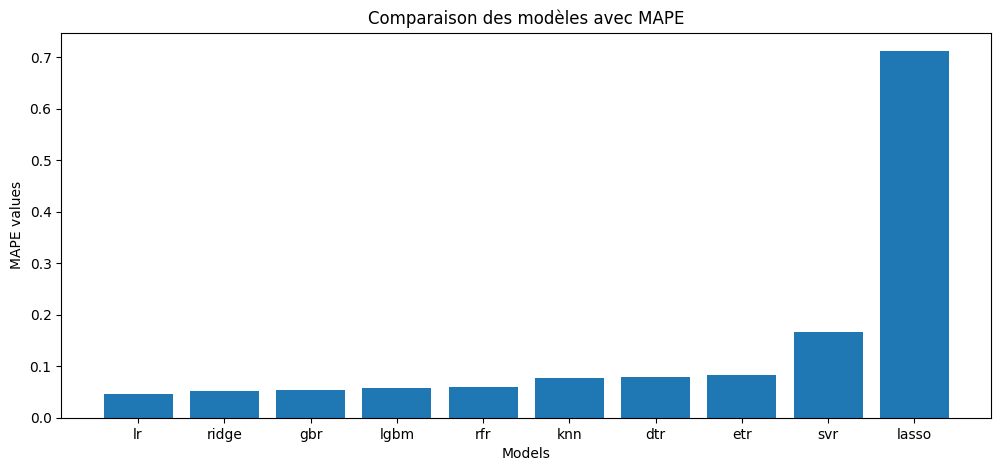

In [119]:
plt.figure(figsize=(12, 5))
plt.title("Comparaison des modèles avec MAPE")
plt.bar(all_mape.index, all_mape.values)
plt.xlabel("Models")
plt.ylabel("MAPE values")
plt.show()

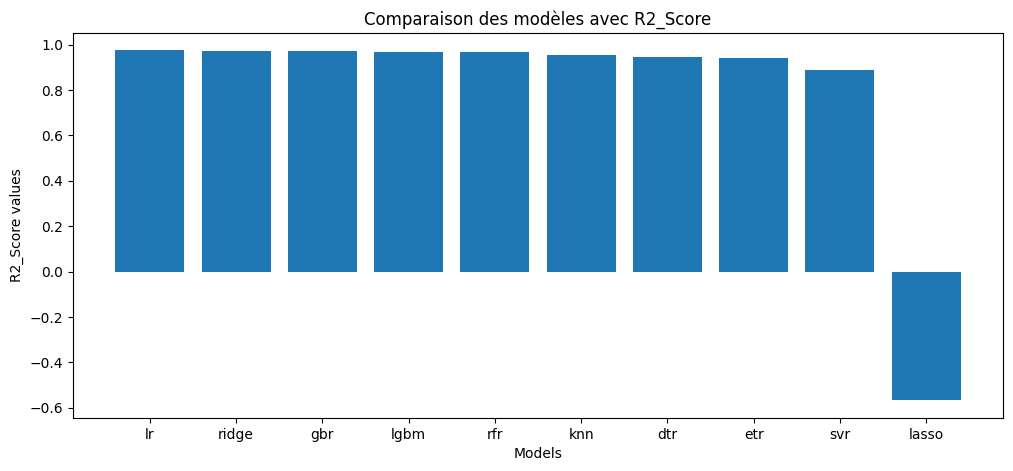

In [120]:
plt.figure(figsize=(12, 5))
plt.title("Comparaison des modèles avec R2_Score")
plt.bar(all_r2.index, all_r2.values)
plt.xlabel("Models")
plt.ylabel("R2_Score values")
plt.show()

**Les meilleurs modèles sont lr et ridge**

In [121]:
td_obj_features

array([[ 2.38100000e-01,  2.39900000e-01,  2.27200000e-01,
         2.36800000e-01,  8.11531557e+07,  2.44528571e-01,
         2.27050000e-01,  6.61616162e-01,  1.07439727e-03,
        -4.82846284e-03,  5.90286011e-03,  2.20470000e-01,
         2.59263819e-01,  1.81676181e-01,  3.49994725e-02,
         2.38000000e-01,  2.57000000e-01,  2.34200000e-01]])

In [122]:
scaled_today_data = scaler.transform(td_obj_features)

In [123]:
linear_model = MultiOutputRegressor(LinearRegression())
ridge_model = MultiOutputRegressor(Ridge())

In [124]:
linear_model.fit(X_train_scaled, y_train)

,estimator,LinearRegression()
,n_jobs,None
,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [125]:
ridge_model.fit(X_train_scaled, y_train)

,estimator,Ridge()
,n_jobs,None
,alpha,1.0
,fit_intercept,True
,copy_X,True
,max_iter,None
,tol,0.0001
,solver,'auto'
,positive,False
,random_state,None


In [126]:
linear_model.predict(X_test_scaled)

array([[0.65897032, 0.60032309, 0.62462281],
       [0.72125155, 0.65938078, 0.68118225],
       [0.76087093, 0.70190276, 0.71763277],
       [0.68709533, 0.60594469, 0.64891814],
       [0.76665267, 0.69252458, 0.71141984],
       [0.76670319, 0.70909488, 0.72920492],
       [0.76659019, 0.70445925, 0.72473343],
       [0.81778845, 0.74230492, 0.76719405],
       [0.8499921 , 0.76184859, 0.80059964],
       [0.82097123, 0.73187307, 0.77294812],
       [0.81916348, 0.73803139, 0.7687338 ],
       [0.81425733, 0.73911377, 0.76321573],
       [0.79772887, 0.72653503, 0.75476296],
       [0.77843495, 0.70779073, 0.73651998],
       [0.74367368, 0.65987679, 0.70290423],
       [0.72683816, 0.66444857, 0.68660763],
       [0.73885991, 0.67372365, 0.69168004],
       [0.72954989, 0.67036653, 0.6927108 ],
       [0.7080523 , 0.63661329, 0.66736611],
       [0.69833456, 0.63861023, 0.66562784],
       [0.67775114, 0.61271559, 0.64728255],
       [0.63379026, 0.55735689, 0.58816535],
       [0.

In [127]:
ridge_model.predict(X_test_scaled)

array([[0.66875474, 0.60650251, 0.63599056],
       [0.71183365, 0.64084375, 0.67152051],
       [0.75264168, 0.67929336, 0.71070366],
       [0.70306601, 0.62536948, 0.66379147],
       [0.74879299, 0.66153777, 0.69810122],
       [0.76938257, 0.68720393, 0.72377397],
       [0.77222885, 0.69293127, 0.72731979],
       [0.81060994, 0.72219014, 0.75926447],
       [0.85006288, 0.74238586, 0.78977894],
       [0.82884123, 0.72723388, 0.77381293],
       [0.83517589, 0.74265666, 0.78349285],
       [0.82457442, 0.73429622, 0.7747275 ],
       [0.80936457, 0.7229646 , 0.76281237],
       [0.78914838, 0.70653811, 0.74493856],
       [0.75077596, 0.65959923, 0.70391068],
       [0.71523933, 0.63553839, 0.67393418],
       [0.72418716, 0.64504501, 0.68192017],
       [0.71807226, 0.64372478, 0.67947754],
       [0.69848138, 0.62476888, 0.66058328],
       [0.6853983 , 0.61994348, 0.65166817],
       [0.6703941 , 0.60636306, 0.63779524],
       [0.63770964, 0.56399395, 0.60048061],
       [0.

In [128]:
(linear_model.predict(X_test_scaled)+ridge_model.predict(X_test_scaled))/2

array([[0.66386253, 0.6034128 , 0.63030669],
       [0.7165426 , 0.65011226, 0.67635138],
       [0.75675631, 0.69059806, 0.71416821],
       [0.69508067, 0.61565709, 0.65635481],
       [0.75772283, 0.67703117, 0.70476053],
       [0.76804288, 0.69814941, 0.72648945],
       [0.76940952, 0.69869526, 0.72602661],
       [0.81419919, 0.73224753, 0.76322926],
       [0.85002749, 0.75211723, 0.79518929],
       [0.82490623, 0.72955348, 0.77338053],
       [0.82716968, 0.74034402, 0.77611332],
       [0.81941587, 0.736705  , 0.76897161],
       [0.80354672, 0.72474982, 0.75878766],
       [0.78379167, 0.70716442, 0.74072927],
       [0.74722482, 0.65973801, 0.70340746],
       [0.72103875, 0.64999348, 0.68027091],
       [0.73152353, 0.65938433, 0.68680011],
       [0.72381107, 0.65704566, 0.68609417],
       [0.70326684, 0.63069109, 0.66397469],
       [0.69186643, 0.62927686, 0.65864801],
       [0.67407262, 0.60953933, 0.64253889],
       [0.63574995, 0.56067542, 0.59432298],
       [0.

In [129]:
y_test.tail()

,Next_Day_High,Next_Day_Low,Next_Day_Close
date,,,
2026-01-03,0.2526,0.2377,0.2507
2026-01-04,0.2592,0.2385,0.2527
2026-01-05,0.2633,0.2410,0.2569
2026-01-06,0.2570,0.2342,0.2380
2026-01-07,0.2399,0.2272,0.2368


In [130]:
ena_ohlcv.tail()

,open,high,low,close,volume
date,,,,,
2026-01-04,0.2391,0.2526,0.2377,0.2507,1.111553e+08
2026-01-05,0.2506,0.2592,0.2385,0.2527,1.954056e+08
2026-01-06,0.2527,0.2633,0.2410,0.2569,2.254839e+08
2026-01-07,0.2568,0.2570,0.2342,0.2380,1.664102e+08
2026-01-08,0.2381,0.2399,0.2272,0.2368,8.115316e+07


In [131]:
linear_model.predict(scaled_today_data)

array([[0.25493406, 0.2330678 , 0.24798569]])

In [132]:
ridge_model.predict(scaled_today_data)

array([[0.26644493, 0.24904932, 0.25934593]])

In [133]:
linear_model.predict(scaled_today_data)/2+ridge_model.predict(scaled_today_data)/2

array([[0.26068949, 0.24105856, 0.25366581]])

In [134]:
import joblib

In [135]:
joblib.dump(scaler, "mm_scaler.pkl")
joblib.dump(linear_model, "linear_model.pkl")
joblib.dump(ridge_model, "ridge_model.pkl")

['ridge_model.pkl']

# Experiment Tracking with MLflow

In [136]:
import mlflow
mlflow.set_experiment("ENA_USDT_Price_Prediction")
mlflow.set_tracking_uri("http://127.0.0.1:5000")

In [137]:
for idx, model_name in enumerate(models):
    with mlflow.start_run(run_name=f"MultiOutput_{model_name}"):
        model = models[model_name]
        
        # Let's retrieve metrics  
        train_mape = all_train_mape[idx]
        test_mape = all_test_mape[idx]
        train_r2 = all_train_r2[idx]
        test_r2 = all_test_r2[idx]
        
        # Let's save parameters, metrics and models in MLflow (or start tracking with mlflow)
        mlflow.log_param("model_name", "MultiOutput_"+model_name)
        mlflow.log_metric("train_mape", train_mape)
        mlflow.log_metric("test_mape", test_mape)
        mlflow.log_metric("train_r2", train_r2)
        mlflow.log_metric("test_r2", test_r2)
        
        # Logging model
        if model_name == "lgbm":
            mlflow.lightgbm.log_model(model, artifact_path="model")
        else:
            mlflow.sklearn.log_model(model, artifact_path="model")

2026/01/09 12:20:36 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


🏃 View run MultiOutput_lr at: http://127.0.0.1:5000/#/experiments/1/runs/f09d73a9eeba48e38e1b75a73ec893b1
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


2026/01/09 12:20:53 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


🏃 View run MultiOutput_ridge at: http://127.0.0.1:5000/#/experiments/1/runs/1d373b0ae65d496eb23472cfecbd6346
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


2026/01/09 12:21:07 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


🏃 View run MultiOutput_lasso at: http://127.0.0.1:5000/#/experiments/1/runs/946b218f33b74dfb92d9d81a7c492ad1
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


... (8 outputs left out)

2026/01/09 12:22:19 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


🏃 View run MultiOutput_knn at: http://127.0.0.1:5000/#/experiments/1/runs/6d24416eda7845f083aef48b74764ac3
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


2026/01/09 12:22:31 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


🏃 View run MultiOutput_lgbm at: http://127.0.0.1:5000/#/experiments/1/runs/6ea8b1f5ef284ca6904b60b55ace7df7
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
